# Détection de joueurs de football potentiellement sous-évalués sur le marché des transferts

**Projet Neural Network and Deep Learning**

### Anaëlle Pollart

## Contexte et objectif

L'objectif de ce projet est d'utiliser le Deep Learning pour estimer la valeur marchande des joueurs de football à partir de leur profil et de leurs statistiques.

Le modèle va prédire une valeur pour chaque joueur. Cette prédiction sera ensuite comparée à sa vraie valeur marchande. Un joueur dont la valeur prédite est supérieure à sa valeur réelle pourra être considéré comme potentiellement sous-évalué selon le modèle. Cela ne veut pas forcément dire qu'il est réellement sous-évalué, car certaines informations ne sont pas présentes dans les données.

Il s'agit d'un problème de régression, car le modèle doit prédire une valeur numérique. Le modèle utilisé est un réseau de neurones dense, aussi appelé Multi-Layer Perceptron ou MLP.

Le notebook contient plusieurs étapes : analyse exploratoire, préparation des données, modèle de référence, modèle profond, amélioration du modèle, puis analyse critique des résultats.

## Dataset

Source : [Football Data from Transfermarkt](https://www.kaggle.com/datasets/davidcariboo/player-scores), Kaggle (davidcariboo).

Le dataset contient plusieurs fichiers csv reliés grâce à l'identifiant des joueurs (player_id). 

Uniquement 4 fichiers csv sont utilisés dans ce projet :
- `players.csv` : profil de chaque joueur (poste, date de naissance, nationalité, club, championnat, valeur marchande actuelle)
- `appearances.csv` : une ligne par match joué par un joueur (buts, passes décisives, minutes jouées, cartons)
- `player_valuations.csv` : historique de la valeur marchande d'un joueur dans le temps
- `competitions.csv` : nom complet de chaque championnat, pour rendre les graphiques plus lisibles

## Plan du notebook

1. Imports et configuration
2. Chargement des données
3. Analyse exploratoire (EDA)
4. Préparation des données pour la modélisation
5. Modèle de référence (baseline)
6. Architecture Deep Learning (MLP)
7. Optimisation et amélioration
8. Évaluation du modèle final
9. Conclusion

## 1. Imports et configuration

In [35]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from keras import layers, regularizers

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# On fixe une seed pour que les résultats soient reproductibles d'une exécution à l'autre.
np.random.seed(42)
tf.random.set_seed(42)

On créer la fonction format_eur() pour afficher les valeurs en euros de façon plus lisible, par exemple « 90,0 M€ » au lieu de « 90 000 000 ». Elle sera réutilisée dans plusieurs tableaux et graphiques du notebook.

In [36]:
# Fonction utilitaire pour afficher les montants en euros de façon lisible
def format_eur(valeur):
    signe = "-" if valeur < 0 else ""
    valeur = abs(valeur)
    if valeur >= 1_000_000:
        return f"{signe}{valeur / 1_000_000:.1f}M€"
    else:
        return f"{signe}{valeur / 1_000:.0f}k€"

# petit test rapide de la fonction
print(format_eur(90000000))
print(format_eur(700000))

90.0M€
700k€


## 2. Chargement des données

In [37]:
# Chargement des CSV depuis le dossier data/ (télécharger le dataset sur Kaggle si besoin :
# https://www.kaggle.com/datasets/davidcariboo/player-scores et le placer dans data/)
players = pd.read_csv("data/players.csv", low_memory=False)
appearances = pd.read_csv("data/appearances.csv", low_memory=False)
valuations = pd.read_csv("data/player_valuations.csv", low_memory=False)
competitions = pd.read_csv("data/competitions.csv", low_memory=False)

print("players :", players.shape)
print("appearances :", appearances.shape)
print("player_valuations :", valuations.shape)
print("competitions :", competitions.shape)

players : (48380, 26)
appearances : (1889406, 13)
player_valuations : (656301, 6)
competitions : (65, 11)


In [38]:
# Aperçu des premières lignes de players.csv
players.head()

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,...,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,1000000.0,30000000.0
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,...,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,750000.0,8000000.0
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,...,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,1000000.0,34500000.0
3,77,NaN,Lúcio,Lúcio,2012,506,lucio,Brazil,Brasília,Brazil,...,NaN,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/lucio/profil/s...,IT1,Juventus Football Club,200000.0,24500000.0
4,80,Tom,Starke,Tom Starke,2017,27,tom-starke,East Germany (GDR),Freital,Germany,...,IFM,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/tom-starke/pro...,L1,FC Bayern München,100000.0,3000000.0


In [39]:
# Types de colonnes
players.info()

<class 'pandas.DataFrame'>
RangeIndex: 48380 entries, 0 to 48379
Data columns (total 26 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   player_id                             48380 non-null  int64  
 1   first_name                            45255 non-null  str    
 2   last_name                             48380 non-null  str    
 3   name                                  48380 non-null  str    
 4   last_season                           48380 non-null  int64  
 5   current_club_id                       48380 non-null  int64  
 6   player_code                           48380 non-null  str    
 7   country_of_birth                      43065 non-null  str    
 8   city_of_birth                         43343 non-null  str    
 9   country_of_citizenship                48109 non-null  str    
 10  date_of_birth                         48331 non-null  str    
 11  sub_position              

In [40]:
# Valeurs manquantes
players.isna().sum()

player_id                                   0
first_name                               3125
last_name                                   0
name                                        0
last_season                                 0
current_club_id                             0
player_code                                 0
country_of_birth                         5315
city_of_birth                            5037
country_of_citizenship                    271
date_of_birth                              49
sub_position                              505
position                                    0
foot                                     5288
height_in_cm                             3783
contract_expiration_date                16632
agent_name                              22517
image_url                                   0
international_caps                      30025
international_goals                     30025
current_national_team_id                42766
url                               

## 3. Analyse exploratoire des données (EDA)

### 3.1 Distribution de la valeur marchande

In [41]:
# Tranches de valeur marchande, des moins chers aux plus chers
bornes = [0, 100_000, 500_000, 1_000_000, 5_000_000, 10_000_000, 25_000_000, 50_000_000, 100_000_000, 200_000_001]
etiquettes = ['0-100k', '100k-500k', '500k-1M', '1M-5M', '5M-10M', '10M-25M', '25M-50M', '50M-100M', '100M-200M']

valeurs = players['market_value_in_eur'].dropna()
tranche = pd.cut(valeurs, bins=bornes, labels=etiquettes, right=False)

table_distribution = tranche.value_counts().reindex(etiquettes).reset_index()
table_distribution.columns = ['Tranche de valeur', 'Nombre de joueurs']
table_distribution['Part des joueurs'] = (table_distribution['Nombre de joueurs'] / len(valeurs) * 100).round(1).astype(str) + ' %'

# Statistiques de base, avec les montants passés dans format_eur pour rester lisibles
stats = valeurs.describe()
print("count :", int(stats['count']))
for cle in ['mean', 'std', 'min', '25%', '50%', '75%', 'max']:
    print(f"{cle:5s} : {format_eur(stats[cle])}")

table_distribution

count : 41506
mean  : 1.5M€
std   : 5.9M€
min   : 10k€
25%   : 100k€
50%   : 275k€
75%   : 700k€
max   : 200.0M€


,Tranche de valeur,Nombre de joueurs,Part des joueurs
0,0-100k,6798,16.4 %
1,100k-500k,20624,49.7 %
2,500k-1M,5452,13.1 %
3,1M-5M,6115,14.7 %
4,5M-10M,1154,2.8 %
5,10M-25M,869,2.1 %
6,25M-50M,365,0.9 %
7,50M-100M,107,0.3 %
8,100M-200M,22,0.1 %


Le tableau montre que la majorité des joueurs ont une valeur marchande inférieure à 500 000 €. À l’inverse, très peu de joueurs dépassent les 50 millions d’euros. La médiane est d’environ 275 000 €, alors que la valeur maximale atteint 200 millions d’euros.

La distribution est donc très déséquilibrée, avec beaucoup de petites valeurs et quelques valeurs très élevées. Pour réduire cet écart, la valeur marchande sera transformée avec un logarithme avant l’entraînement du modèle (section 4). Cela évite que les joueurs les plus chers aient trop d’influence sur les résultats.


### 3.2 Répartition par poste

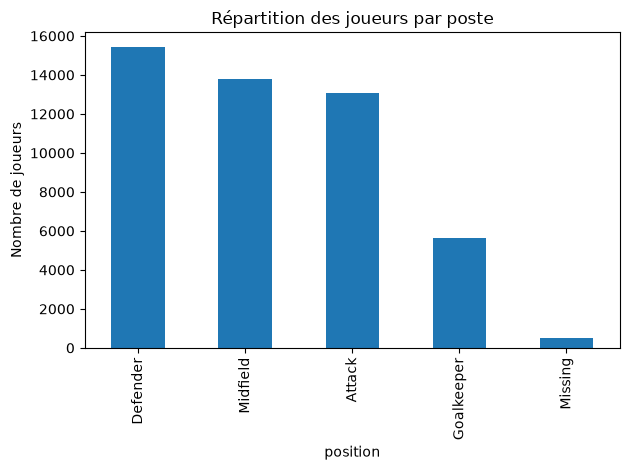

position
Defender      15414
Midfield      13786
Attack        13064
Goalkeeper     5611
Missing         505
Name: count, dtype: int64

In [42]:
# Nombre de joueurs par poste
position_counts = players['position'].value_counts()

plt.figure()
position_counts.plot(kind='bar')
plt.title("Répartition des joueurs par poste")
plt.ylabel("Nombre de joueurs")
plt.tight_layout()
plt.show()

position_counts

Les postes sont à peu près équilibrés entre défenseurs, milieux et attaquants. Il y a moins de gardiens, ce qui est logique : une équipe n'a qu'un seul gardien titulaire, contre plusieurs joueurs de champ à chaque poste. Une petite catégorie "Missing" (poste non renseigné) sera retirée du dataset final en section 4.

### 3.3 Nombre de matchs et minutes jouées

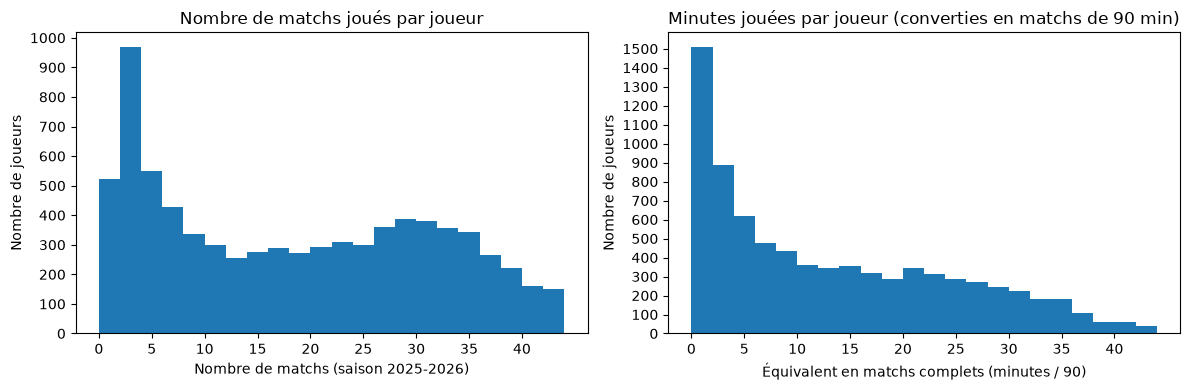

Nombre moyen de matchs joués : 18.9
Temps de jeu moyen (en équivalent matchs de 90 min) : 13.6


In [43]:
# La colonne 'season' regroupe chaque match dans sa saison sportive (par exemple un match joué en janvier 2026 fait partie de la saison 2025-2026, qui commence en juillet/août)
appearances['date'] = pd.to_datetime(appearances['date'])
appearances['season'] = appearances['date'].dt.year - (appearances['date'].dt.month < 7).astype(int)

season_2025 = appearances[appearances['season'] == 2025]
matches_per_player = season_2025.groupby('player_id').size()
minutes_per_player = season_2025.groupby('player_id')['minutes_played'].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(matches_per_player, bins=range(0, 45, 2))
axes[0].set_xticks(range(0, 45, 5))
axes[0].yaxis.set_major_locator(plt.MultipleLocator(100))
axes[0].set_title("Nombre de matchs joués par joueur")
axes[0].set_xlabel("Nombre de matchs (saison 2025-2026)")
axes[0].set_ylabel("Nombre de joueurs")

axes[1].hist(minutes_per_player / 90, bins=range(0, 45, 2))
axes[1].set_xticks(range(0, 45, 5))
axes[1].yaxis.set_major_locator(plt.MultipleLocator(100))
axes[1].set_title("Minutes jouées par joueur (converties en matchs de 90 min)")
axes[1].set_xlabel("Équivalent en matchs complets (minutes / 90)")
axes[1].set_ylabel("Nombre de joueurs")

plt.tight_layout()
plt.show()

print("Nombre moyen de matchs joués :", round(matches_per_player.mean(), 1))
print("Temps de jeu moyen (en équivalent matchs de 90 min) :", round((minutes_per_player / 90).mean(), 1))

Les deux graphiques représentent le temps de jeu des joueurs de deux manières différentes. Le premier affiche le nombre de matchs disputés, tandis que le second convertit les minutes jouées en équivalent de matchs complets de 90 minutes.

Les deux distributions sont assez proches, mais les valeurs du second graphique sont généralement plus faibles. En effet, une apparition ne correspond pas forcément à un match complet : un joueur peut entrer seulement quelques minutes en fin de rencontre.

Beaucoup de joueurs ont participé à peu de matchs (remplaçants, blessures, arrivée en cours de saison). À l'inverse, certains joueurs dépassent l'équivalent de 35 matchs complets.

Cette différence de temps de jeu sera importante pour la suite. Les statistiques d'un joueur ayant très peu joué peuvent être peu représentatives et peu fiables (un seul but sur 2 matchs donne une moyenne trompeuse). Un filtre sur le nombre minimum de minutes sera donc appliqué dans la section 4.

### 3.4 Âge et valeur marchande

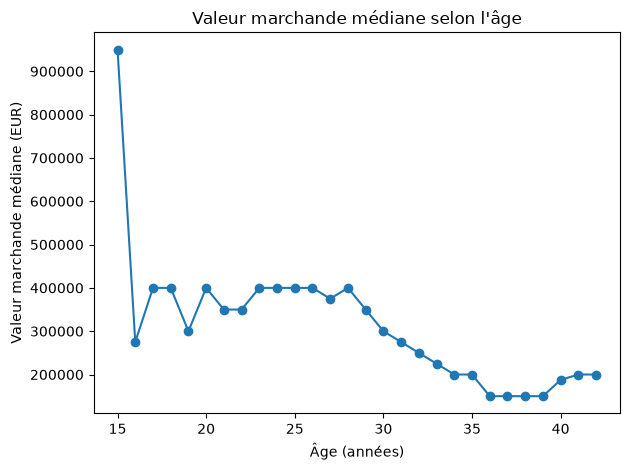

In [44]:
# Calcul de l'âge de chaque joueur à la date de référence
REFERENCE_DATE = pd.Timestamp('2025-08-01')

players['date_of_birth'] = pd.to_datetime(players['date_of_birth'])
players['age'] = (REFERENCE_DATE - players['date_of_birth']).dt.days / 365.25

# Bornes 15-42 ans : au-delà, il ne reste que quelques joueurs isolés,pas assez pour calculer une médiane représentative par âge
age_value = players.dropna(subset=['age', 'market_value_in_eur'])
age_value = age_value[(age_value['age'] >= 15) & (age_value['age'] <= 42)]

median_value_by_age = age_value.groupby(age_value['age'].round())['market_value_in_eur'].median()

plt.figure()
median_value_by_age.plot(kind='line', marker='o')
plt.title("Valeur marchande médiane selon l'âge")
plt.xlabel("Âge (années)")
plt.ylabel("Valeur marchande médiane (EUR)")
plt.tight_layout()
plt.show()

La valeur marchande médiane reste assez stable entre 17 et 28 ans (environ 300 000 à 400 000 EUR). Elle diminue ensuite de façon régulière après 29 ans, jusqu'à la fin de carrière. Les joueurs plus âgés valent donc en moyenne moins cher, ce qui correspond à la réalité du football : moins d'années de carrière restantes, risque de blessure plus élevé.

Le point à 15 ans, au-dessus du reste de la courbe, ne doit pas être interprété comme une vraie tendance. Seuls 2 joueurs de 15 ans ont une valeur marchande renseignée dans le dataset (Linus Güther, 1M€, et Eirik Granaas, 900k€). La médiane est donc calculée sur un échantillon bien trop petit pour être représentatif.

### 3.5 Évolution de la valeur marchande dans le temps

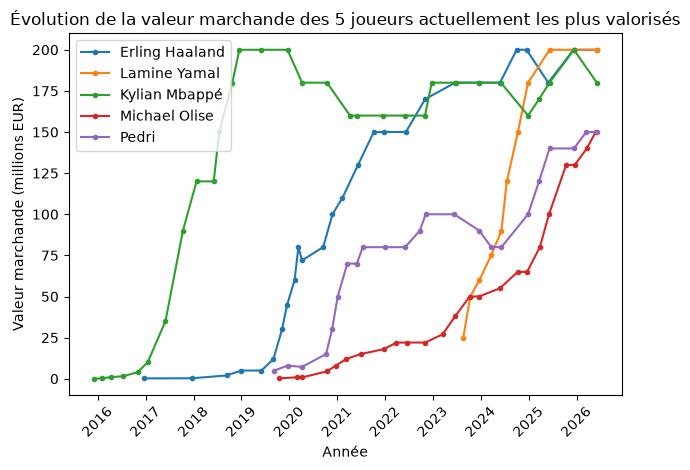

In [45]:
# Historique de valeur des joueurs actuellement les plus chers
valuations['date'] = pd.to_datetime(valuations['date'])

top_players = players.nlargest(5, 'market_value_in_eur')[['player_id', 'name']]

plt.figure()
for _, row in top_players.iterrows():
    history = valuations[valuations['player_id'] == row['player_id']].sort_values('date')
    # Valeur convertie en millions d'euros pour un axe plus lisble
    plt.plot(history['date'], history['market_value_in_eur'] / 1_000_000, marker='.', label=row['name'])

# Un repère par année
annees = pd.date_range('2016-01-01', '2026-01-01', freq='YS')
plt.xticks(annees, [str(a.year) for a in annees], rotation=45)

plt.title("Évolution de la valeur marchande des 5 joueurs actuellement les plus valorisés")
plt.xlabel("Année")
plt.ylabel("Valeur marchande (millions EUR)")
plt.legend()
plt.tight_layout()
plt.show()

Ce graphique s'appuie sur `player_valuations.csv`, une table différente de celle utilisée pour les graphiques précédents. 

Les cinq joueurs affichés (Erling Haaland, Lamine Yamal, Kylian Mbappé, Michael Olise, Pedri) sont actuellements les joueurs les plus côtés du marché. Leurs courbes correspondent bien à ce qu'on peut observer dans la réalité. Kylian Mbappé progresse fortement dès 2017 (10M€ en janvier, 90M€ en octobre), au moment de ses débuts à l'AS Monaco puis de son transfert au PSG. Lamine Yamal apparaît plus tard dans l'historique (25M€ fin 2023) et grimpe fortement en 2024 (75M€ en mars, 200M€ en fin d'année), ce qui correspond à sa percée médiatique pendant l'Euro 2024. 

On remarque aussi que certaines valeurs diminuent après avoir atteint un maximum. Une valeur marchande n'augmente donc pas forcément de manière continue au cours de la carrière d'un joueur.

La valeur maximale observée dans ce fichier est de 200 millions d'euros.

### 3.6 Sélections en équipe nationale et valeur marchande

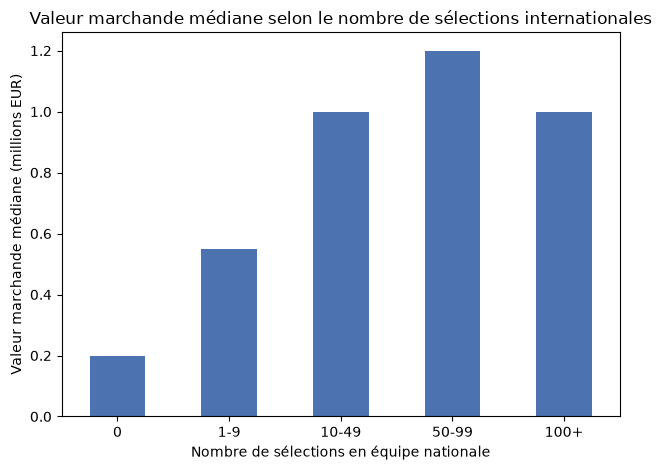

In [46]:
# Regroupement des joueurs par nombre de sélections internationales
intl = players.dropna(subset=['market_value_in_eur']).copy()
intl['international_caps'] = intl['international_caps'].fillna(0)

# Les joueurs sont regroupés en catégories selon leur nombre de sélections, plutôt que de garder un nombre exact (+ simple à lire sur le graphique)
bornes_caps = [0, 1, 10, 50, 100, 1000]
etiquettes_caps = ['0', '1-9', '10-49', '50-99', '100+']
intl['groupe_caps'] = pd.cut(intl['international_caps'], bins=bornes_caps, labels=etiquettes_caps, right=False)

valeur_mediane_par_caps = intl.groupby('groupe_caps', observed=True)['market_value_in_eur'].median() / 1_000_000

plt.figure()
valeur_mediane_par_caps.reindex(etiquettes_caps).plot(kind='bar', color='#4C72B0')
plt.xlabel("Nombre de sélections en équipe nationale")
plt.ylabel("Valeur marchande médiane (millions EUR)")
plt.title("Valeur marchande médiane selon le nombre de sélections internationales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Chaque barre représente la valeur marchande médiane des joueurs en fonction de leur nombre de sélections en équipe nationale.

La tendance générale montre que les joueurs ayant beaucoup de sélections possèdent généralement une valeur marchande plus élevée. La médiane passe d'environ 200 000 € pour les joueurs jamais sélectionnés à environ 1 million d'euros pour ceux ayant au moins 100 sélections.

La progression n'est cependant pas parfaitement régulière. Le groupe ayant entre 50 et 99 sélections possède par exemple une médiane légèrement supérieure à celle du groupe ayant plus de 100 sélections. Cela peut notamment venir du nombre plus faible de joueurs dans ces catégories.

Le nombre de sélections semble donc être une variable intéressante, mais il ne permet pas d'expliquer seul la valeur d'un joueur. Un jeune joueur peut déjà avoir une valeur élevée avant d'avoir beaucoup joué avec son équipe nationale.


### 3.7 Valeur marchande moyenne par poste

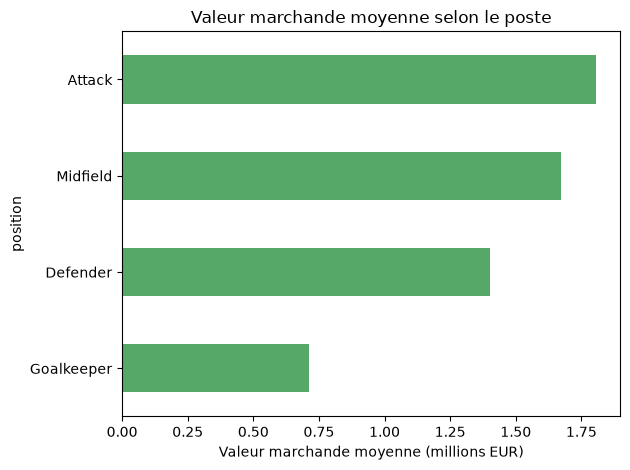

In [47]:
# Poste 'Missing' retiré (données non renseignées, voir 3.2)
# La moyenne est utilisée plutôt que la médiane ici, sinon les 3 postes de joueurs de champ sont à égalité parfaite et on ne voit pas de différence sur le graphique
valeur_par_poste = players[players['position'] != 'Missing'].groupby('position')['market_value_in_eur'].mean()
valeur_par_poste = (valeur_par_poste / 1_000_000).sort_values()

plt.figure()
valeur_par_poste.plot(kind='barh', color='#55A868')
plt.xlabel("Valeur marchande moyenne (millions EUR)")
plt.title("Valeur marchande moyenne selon le poste")
plt.tight_layout()
plt.show()

Les attaquants ont la valeur marchande moyenne la plus élevée (1.8M€), suivis des milieux (1.7M€) et des défenseurs (1.4M€). Les gardiens de but sont la catégorie la moins valorisée (0.7M€). Cet écart correspond à une réalité connue du marché des transferts : les buts et les passes décisives sont les statistiques les plus visibles et les plus valorisées, et elles sont produites en majorité par les attaquants et les milieux offensifs. En médiane, ces trois postes de joueurs de champ sont d'ailleurs exactement à égalité (300k€ chacun) : la moyenne est donc nécessaire ici pour les distinguer, car elle est plus sensible aux quelques stars très bien payées de chaque poste. Le poste est donc gardé comme variable d'entrée du modèle (section 4), sous forme de catégorie plutôt que de nombre.

## 4. Préparation des données pour la modélisation

### 4.1 Choix de la période de référence

Les statistiques de performance doivent être calculées sur une période précise. La saison 2025-2026 (août 2025 à juillet 2026) est utilisée comme période de référence, car il s'agit de la saison la plus récente et de celle qui contient le plus de matchs et de joueurs dans le dataset, comme le montre le tableau ci-dessous.

Les variables liées aux performances, comme les matchs, les minutes, les buts, les passes décisives et les cartons, correspondent uniquement à cette saison. Les informations du profil, comme l'âge, la taille et le nombre de sélections, viennent de la version la plus récente disponible dans le fichier players.csv.

La valeur marchande utilisée comme cible sera la dernière valeur disponible avant la date de référence.

In [48]:
# Nombre de matchs et de joueurs uniques sur les dernières saisons
matches_per_season = appearances.groupby('season').size().tail(6)
players_per_season = appearances.groupby('season')['player_id'].nunique().tail(6)

comparison_seasons = pd.DataFrame({
    'apparitions': matches_per_season,
    'joueurs_uniques': players_per_season,
})
comparison_seasons

,apparitions,joueurs_uniques
season,,
2020,149665,7608
2021,131656,6008
2022,142620,7098
2023,143531,7150
2024,148396,7852
2025,151732,8009


### 4.2 Calcul des statistiques de performance par joueur

Chaque ligne de `appearances.csv` correspond à un seul match. Cette étape regroupe ces lignes par joueur, pour obtenir sur la saison de référence un total de matchs, de minutes, de buts, de passes décisives et de cartons. Les buts et passes décisives sont aussi ramenés à 90 minutes jouées (durée d'un match). Ça permet de comparer plus facilement un titulaire qui joue tous les matchs en entier et un remplaçant qui n'entre en jeu que quelques minutes à chaque fois.

Un filtre garde ensuite seulement les joueurs ayant joué au moins 450 minutes sur la saison (l'équivalent de 5 matchs complets). En dessous de ce seuil, les statistiques par 90 minutes sont calculées sur trop peu de matchs pour être fiables. Par exemple, un seul but marqué en 20 minutes de jeu donnerait, une fois ramené à 90 minutes, une moyenne totalement irréaliste.

In [49]:
SEASON_REF = 2025

season_stats = appearances[appearances['season'] == SEASON_REF].groupby('player_id').agg(
    matches_played=('appearance_id', 'count'),
    minutes_played=('minutes_played', 'sum'),
    goals=('goals', 'sum'),
    assists=('assists', 'sum'),
    yellow_cards=('yellow_cards', 'sum'),
    red_cards=('red_cards', 'sum'),
).reset_index()

# Buts et passes ramenés à 90 minutes, pour comparer équitablement un joueur qui a beaucoup joué et un joueur qui n'a joué que quelques matchs
season_stats['goals_per90'] = season_stats['goals'] / (season_stats['minutes_played'] / 90)
season_stats['assists_per90'] = season_stats['assists'] / (season_stats['minutes_played'] / 90)

# En dessous de 450 minutes jouées, les statistiques par 90 minutes sont calculées sur trop peu de matchs pour être fiables
MIN_MINUTES = 450
season_stats = season_stats[season_stats['minutes_played'] >= MIN_MINUTES]

print(f"Joueurs retenus après filtre de temps de jeu (>= {MIN_MINUTES} minutes) : {len(season_stats)}")
season_stats.head()

Joueurs retenus après filtre de temps de jeu (>= 450 minutes) : 5290


,player_id,matches_played,minutes_played,goals,assists,yellow_cards,red_cards,goals_per90,assists_per90
0,3333,22,946,1,1,2,0,0.095137,0.095137
2,7161,28,1288,3,3,3,0,0.209627,0.209627
4,11530,24,1902,0,0,4,0,0.000000,0.000000
5,12282,31,2610,0,0,1,0,0.000000,0.000000
7,15452,9,570,0,1,2,0,0.000000,0.157895


### 4.3 Valeur marchande de référence

Cette étape associe à chaque joueur la cible que le modèle doit apprendre à prédire. `player_valuations.csv` contient plusieurs valeurs marchandes par joueur, une à chaque fois que Transfermarkt a mis à jour son estimation, chacune avec sa propre date. Cette table est utilisée plutôt que la colonne `market_value_in_eur` de `players.csv` : cette dernière n'a pas de date associée, donc impossible de savoir si elle correspond bien à la période des statistiques de performance (certaines valeurs pourraient être anciennes de plusieurs années). 

Avec `player_valuations.csv`, on garde pour chaque joueur seulement la valeur la plus récente avant la date de référence (`groupby('player_id').last()` après avoir trié par date). On obtient ainsi une seule valeur marchande par joueur, qui servira de cible au modèle.

In [50]:
# Dernière valeur connue de chaque joueur avant la date de référence
VALUATION_CUTOFF = pd.Timestamp('2026-07-01')

recent_valuations = valuations[valuations['date'] <= VALUATION_CUTOFF].sort_values('date')
latest_valuation = recent_valuations.groupby('player_id').last()[['market_value_in_eur', 'date']]
latest_valuation = latest_valuation.rename(columns={'date': 'valuation_date'})

season_stats = season_stats.merge(latest_valuation, on='player_id', how='inner')
print(f"Joueurs avec une valeur marchande disponible : {len(season_stats)}")

Joueurs avec une valeur marchande disponible : 5289


### 4.4 Fusion avec le profil du joueur

Point important : `players.csv` contient aussi une colonne `highest_market_value_in_eur`, la plus haute valeur jamais atteinte par le joueur. Cette colonne n'est volontairement pas utilisée comme variable d'entrée du modèle. Elle est trop proche de la valeur actuelle qu'on cherche justement à prédire : l'utiliser reviendrait presque à donner la réponse au modèle.

In [51]:
# Valeurs manquantes de sélections/buts internationaux remplacées par 0 : on suppose que l'absence de donnée veut dire que le joueur n'a jamais été sélectionné
players['international_caps'] = players['international_caps'].fillna(0)
players['international_goals'] = players['international_goals'].fillna(0)
# height_in_cm est laissée avec des valeurs manquantes ici : elle sera complétée plus tard avec la médiane du train set uniquement (section 4.8), pour ne pas utiliser les joueurs du validation/test set dans le calcul de cette médiane

dataset = season_stats.merge(
    players[['player_id', 'position', 'age', 'height_in_cm', 'international_caps',
             'international_goals', 'current_club_domestic_competition_id']],
    on='player_id', how='left'
)

before = len(dataset)
dataset = dataset.dropna(subset=['position', 'age'])
dataset = dataset[dataset['position'] != 'Missing']
after = len(dataset)
print(f"Lignes supprimées (poste ou âge manquant) : {before - after} sur {before}")

dataset.head()

Lignes supprimées (poste ou âge manquant) : 0 sur 5289


,player_id,matches_played,minutes_played,goals,assists,yellow_cards,red_cards,goals_per90,assists_per90,market_value_in_eur,valuation_date,position,age,height_in_cm,international_caps,international_goals,current_club_domestic_competition_id
0,3333,22,946,1,1,2,0,0.095137,0.095137,500000,2026-06-03,Midfield,39.572895,175.0,61.0,1.0,GB1
1,7161,28,1288,3,3,3,0,0.209627,0.209627,1500000,2026-05-27,Midfield,33.048597,176.0,23.0,4.0,L1
2,11530,24,1902,0,0,4,0,0.000000,0.000000,200000,2026-05-21,Defender,34.305270,180.0,1.0,0.0,TR1
3,12282,31,2610,0,0,1,0,0.000000,0.000000,1200000,2026-06-05,Defender,35.397673,180.0,108.0,3.0,ES1
4,15452,9,570,0,1,2,0,0.000000,0.157895,700000,2026-05-29,Defender,39.906913,190.0,58.0,0.0,IT1


### 4.5 Encodage du championnat

Le championnat est une variable catégorielle qui contient un grand nombre de valeurs différentes. Pour éviter de créer trop de colonnes, les dix championnats les plus représentés sont conservés séparément. Tous les autres sont regroupés dans une catégorie `Other`.

Un encodage one-hot est ensuite appliqué. Chaque championnat devient donc une colonne contenant 0 ou 1, comme pour le poste du joueur.

Les dix championnats sont sélectionnés à partir du dataset complet. Une méthode plus rigoureuse aurait été de les choisir uniquement à partir du train set. Cependant, ce choix ne dépend pas des valeurs marchandes, mais seulement du nombre de joueurs présents dans chaque championnat.


In [52]:
TOP_N_LEAGUES = 10
top_leagues = dataset['current_club_domestic_competition_id'].value_counts().head(TOP_N_LEAGUES).index
dataset['league_grouped'] = np.where(
    dataset['current_club_domestic_competition_id'].isin(top_leagues),
    dataset['current_club_domestic_competition_id'], 'Other'
)

# competitions.csv donne le nom des championnats à partir de leur code (ex: GB1 -> premier-league)
league_info = competitions.drop_duplicates('competition_id').set_index('competition_id')
LEAGUE_NAMES = {code: league_info['name'].get(code, code) for code in top_leagues}
LEAGUE_NAMES['RU1'] += " (RU)"      # même nom "premier-liga" que l'Ukraine sinon
LEAGUE_NAMES['UKR1'] += " (UKR)"
LEAGUE_NAMES['Other'] = 'Autres championnats'

print("Championnats retenus :")
for code_ligue in top_leagues:
    print(f"  {code_ligue} : {LEAGUE_NAMES[code_ligue]}")

league_dummies = pd.get_dummies(dataset['league_grouped'], prefix='League')
position_dummies = pd.get_dummies(dataset['position'], prefix='Pos')

Championnats retenus :
  GB1 : premier-league
  ES1 : laliga
  IT1 : serie-a
  FR1 : ligue-1
  L1 : bundesliga
  NL1 : eredivisie
  PO1 : liga-portugal
  TR1 : super-lig
  RU1 : premier-liga (RU)
  UKR1 : premier-liga (UKR)


### 4.6 Cible et assemblage du dataset final

La cible du modèle (`log_value`) est calculée ici avec une transformation logarithmique, pour les raisons vues en section 3.1. Toutes les variables retenues jusqu'ici (statistiques de performance, profil, poste encodé, championnat encodé) sont rassemblées dans un seul tableau, `model_df`. C'est ce tableau qui sert de point de départ à la séparation train/validation/test de la section suivante. 

`model_df` contient 30 colonnes au total : les 27 variables explicatives utilisées par le modèle, plus `player_id` (l'identifiant, pas utilisé comme feature), `log_value` (la cible) et `market_value_in_eur` (la valeur brute, gardée pour reconvertir facilement en euros plus tard).

`market_value_in_eur` gardée ici vient de `player_valuations.csv` (la version datée vue en 4.3), pas de la colonne brute de players.csv.

In [53]:
dataset['log_value'] = np.log1p(dataset['market_value_in_eur'])

numeric_features = ['age', 'height_in_cm', 'matches_played', 'minutes_played',
                     'goals', 'assists', 'goals_per90', 'assists_per90',
                     'yellow_cards', 'red_cards', 'international_caps', 'international_goals']

model_df = pd.concat([
    dataset[['player_id'] + numeric_features + ['log_value', 'market_value_in_eur']].reset_index(drop=True),
    position_dummies.reset_index(drop=True),
    league_dummies.reset_index(drop=True),
], axis=1)

# height_in_cm est exclue de ce dropna : ses valeurs manquantes sont comblées plus tard (section 4.8), une fois le train set connu, plutôt que maintenant
cols_a_verifier = [c for c in model_df.columns if c != 'height_in_cm']
model_df = model_df.dropna(subset=cols_a_verifier)
print("Dataset final :", model_df.shape)
model_df.head()

Dataset final : (5289, 30)


,player_id,age,height_in_cm,matches_played,minutes_played,goals,assists,goals_per90,assists_per90,yellow_cards,...,League_FR1,League_GB1,League_IT1,League_L1,League_NL1,League_Other,League_PO1,League_RU1,League_TR1,League_UKR1
0,3333,39.572895,175.0,22,946,1,1,0.095137,0.095137,2,...,False,True,False,False,False,False,False,False,False,False
1,7161,33.048597,176.0,28,1288,3,3,0.209627,0.209627,3,...,False,False,False,True,False,False,False,False,False,False
2,11530,34.305270,180.0,24,1902,0,0,0.000000,0.000000,4,...,False,False,False,False,False,False,False,False,True,False
3,12282,35.397673,180.0,31,2610,0,0,0.000000,0.000000,1,...,False,False,False,False,False,False,False,False,False,False
4,15452,39.906913,190.0,9,570,0,1,0.000000,0.157895,2,...,False,False,True,False,False,False,False,False,False,False


### 4.7 Corrélations entre variables numériques

Avant de passer à la modélisation, une matrice de corrélation est calculée entre les variables numériques retenues et la cible (`log_value`), pour identifier lesquelles sont les plus liées à la valeur marchande et repérer d'éventuelles redondances entre elles.

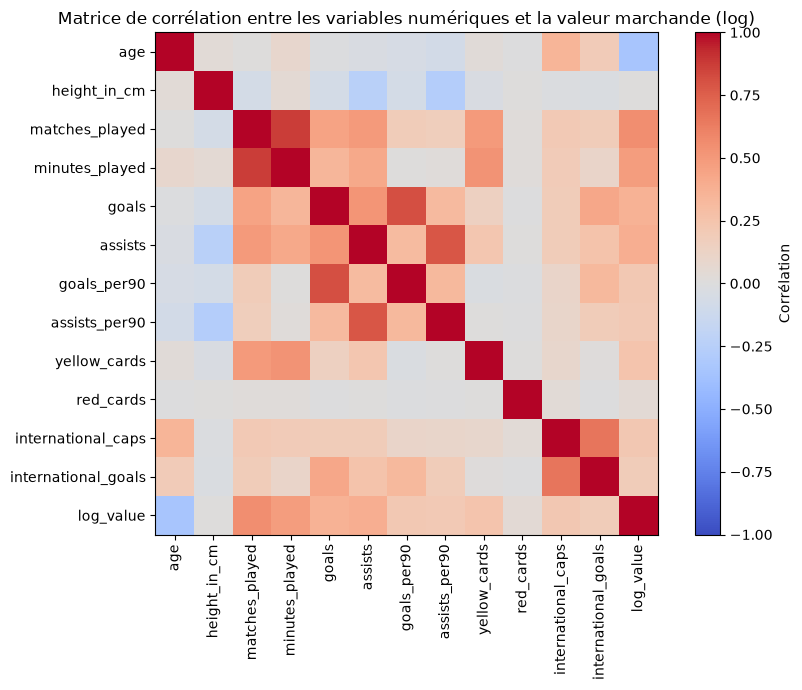

log_value              1.000000
matches_played         0.547797
minutes_played         0.478647
assists                0.390259
goals                  0.361420
yellow_cards           0.249261
international_caps     0.219243
goals_per90            0.216669
assists_per90          0.207627
international_goals    0.186770
red_cards              0.046818
height_in_cm           0.000784
age                   -0.338769
Name: log_value, dtype: float64

In [54]:
# Corrélation entre les variables numériques et la cible (log_value), pour identifier les variables les plus liées à la valeur marchande
corr_matrix = model_df[numeric_features + ['log_value']].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Corrélation')
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)
plt.title("Matrice de corrélation entre les variables numériques et la valeur marchande (log)")
plt.tight_layout()
plt.show()

corr_matrix['log_value'].sort_values(ascending=False)

Le temps de jeu est la variable la plus corrélée à la valeur marchande. Le nombre de matchs joués (corrélation de 0,55) et les minutes jouées (0,48) dépassent les statistiques offensives brutes : les passes décisives (0,39) et les buts (0,36). Une explication possible : un joueur régulièrement titularisé a généralement la confiance de son club, et ça peut se refléter dans sa valeur marchande. Mais cette corrélation ne prouve pas ce lien de cause à effet à elle seule. Les statistiques ramenées à 90 minutes (buts/90 : 0,22 ; passes/90 : 0,21) sont moins corrélées que les totaux bruts. Dans cet échantillon, le volume de jeu compte donc plus que l'efficacité par minute. L'âge est la seule variable nettement corrélée négativement (-0,34), ce qui est cohérent avec le déclin de valeur après 29 ans observé en section 3.4. La taille, elle, n'a presque aucun lien linéaire avec la valeur marchande sur cet échantillon.

Certaines variables sont aussi fortement corrélées entre elles : le nombre de matchs et les minutes jouées (0,87), ou les buts et leur équivalent par 90 minutes (0,81), mesurent en partie la même chose. Mais elle explique pourquoi certaines de ces variables apportent une information proche l'une de l'autre au modèle. Les cartons et les statistiques internationales (yellow_cards, red_cards, international_caps, international_goals) ont individuellement une corrélation plus faible avec la cible. Elles sont quand même gardées, car un réseau de neurones peut combiner plusieurs signaux faibles, contrairement à une simple lecture de corrélation individuelle.

### 4.8 Séparation train / validation / test

Ici, on ne cherche pas à prédire l'avenir à partir du passé, contrairement à un problème où l'on prédit un événement futur. On cherche plutôt à estimer, à un instant donné, la relation entre la performance d'un joueur et sa valeur marchande. C'est pour ça qu'un découpage aléatoire du dataset est utilisé, plutôt qu'un découpage par date.

In [55]:
feature_cols = numeric_features + list(position_dummies.columns) + list(league_dummies.columns)

# On mélange les lignes du dataset, puis on découpe en 70% train / 15% validation / 15% test
model_df_shuffled = model_df.sample(frac=1, random_state=42).reset_index(drop=True)

n = len(model_df_shuffled)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = model_df_shuffled.iloc[:train_end].copy()
val_df = model_df_shuffled.iloc[train_end:val_end].copy()
test_df = model_df_shuffled.iloc[val_end:].copy()

# La taille manquante est complétée avec la médiane du train set uniquement, puis cette même valeur (calculée seulement sur le train) est appliquée aux trois ensembles
median_height_train = train_df['height_in_cm'].median()
train_df['height_in_cm'] = train_df['height_in_cm'].fillna(median_height_train)
val_df['height_in_cm'] = val_df['height_in_cm'].fillna(median_height_train)
test_df['height_in_cm'] = test_df['height_in_cm'].fillna(median_height_train)

X_train = train_df[feature_cols].values.astype('float32')
X_val = val_df[feature_cols].values.astype('float32')
X_test = test_df[feature_cols].values.astype('float32')

y_train = train_df['log_value'].values.astype('float32')
y_val = val_df['log_value'].values.astype('float32')
y_test = test_df['log_value'].values.astype('float32')

# Normalisation : moyenne et écart-type calculés uniquement sur le train, puis appliqués aux trois ensembles
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1
X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)

X_train : (3702, 27)
X_val   : (793, 27)
X_test  : (794, 27)


### 4.9 Une précaution : limiter les prédictions extrêmes

La cible du modèle est en échelle logarithmique (`log_value`). Pour revenir à des euros, il faut faire l'opération inverse (`expm1`). 

Cette opération amplifie fortement les erreurs : une petite erreur en échelle logarithmique peut devenir énorme une fois reconvertie en euros. Si le modèle prédit une valeur un peu au-dessus de tout ce qu'il a vu à l'entraînement, cette prédiction peut devenir absurde une fois reconvertie (plusieurs milliards d'euros par exemple), et ça fausserait complètement la MAE calculée plus loin.

Pour éviter qu'une prédiction extrême ait trop d'influence sur les métriques, les valeurs prédites sont limitées à la valeur maximale observée dans le train set, soit 200 millions d'euros. La même règle est appliquée à tous les modèles.

L'erreur absolue médiane est également calculée en complément de la MAE. Elle est moins sensible à quelques erreurs très élevées et permet de mieux représenter l'erreur obtenue pour la majorité des joueurs.

In [56]:
# Fonctions utilitaires pour convertir les prédictions en euros et les évaluer
from sklearn.metrics import median_absolute_error

VALEUR_LOG_MAX = y_train.max()

def to_eur(y_pred_log):
    """Convertit une prédiction en échelle log vers des euros, en la plafonnant
    d'abord à la valeur maximale observée à l'entraînement."""
    return np.expm1(np.clip(y_pred_log, a_min=None, a_max=VALEUR_LOG_MAX))

def evaluate_eur(y_true_log, y_pred_log, nom_modele):
    y_true_eur = np.expm1(y_true_log)
    y_pred_eur = to_eur(y_pred_log)
    mae = mean_absolute_error(y_true_eur, y_pred_eur)
    medae = median_absolute_error(y_true_eur, y_pred_eur)
    print(f"{nom_modele} - MAE : {format_eur(mae)} | Erreur absolue médiane : {format_eur(medae)}")
    return mae, medae

## 5. Modèle de référence (baseline)

### 5.1 Baseline triviale : toujours prédire la valeur médiane

In [57]:
# Cette "baseline" ne regarde pas les statistiques du joueur : elle prédit toujours la même valeur (la médiane du train set). Tout modèle utile doit faire mieux.
# Évaluée ici sur le validation set
median_log_value = np.median(y_train)
y_pred_trivial_val = np.full_like(y_val, fill_value=median_log_value)

mae_trivial_val, medae_trivial_val = evaluate_eur(y_val, y_pred_trivial_val, "Baseline triviale (médiane) - validation")

Baseline triviale (médiane) - validation - MAE : 7.1M€ | Erreur absolue médiane : 2.0M€


### 5.2 Baseline linéaire

La deuxième référence est le plus simple des réseaux de neurones possibles : une seule couche `Dense` sans activation. Ça revient mathématiquement à une régression linéaire classique. Contrairement à la baseline triviale, il utilise les variables du dataset pour effectuer ses prédictions. Il servira de point de comparaison avec le MLP de la section 6.

In [218]:
def build_linear_baseline(input_dim):
    model = keras.Sequential(name="Baseline_Lineaire")
    model.add(keras.layers.Input(shape=(input_dim,), name="InputLayer"))
    model.add(keras.layers.Dense(1, name="Output"))
    # lr plus élevé que d'habitude (0.01 au lieu de 0.001) : ça converge plus vite sur ce
    # modèle tout simple, et vu qu'il n'y a qu'une seule couche le risque de diverger est faible
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss='mse', metrics=['mae'])
    return model

baseline_model = build_linear_baseline(X_train.shape[1])
baseline_model.summary()

Model: "Baseline_Lineaire"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Output (Dense)                  │ (None, 1)              │            28 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28 (112.00 B)

 Trainable params: 28 (112.00 B)

 Non-trainable params: 0 (0.00 B)

In [219]:
# Entraînement de la baseline linéaire
history_baseline = baseline_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    verbose=0
)

y_pred_baseline_log = baseline_model.predict(X_val, verbose=0).flatten()
mae_baseline_val, medae_baseline_val = evaluate_eur(y_val, y_pred_baseline_log, "Baseline linéaire - validation")

Baseline linéaire - validation - MAE : 4.0M€ | Erreur absolue médiane : 1.2M€


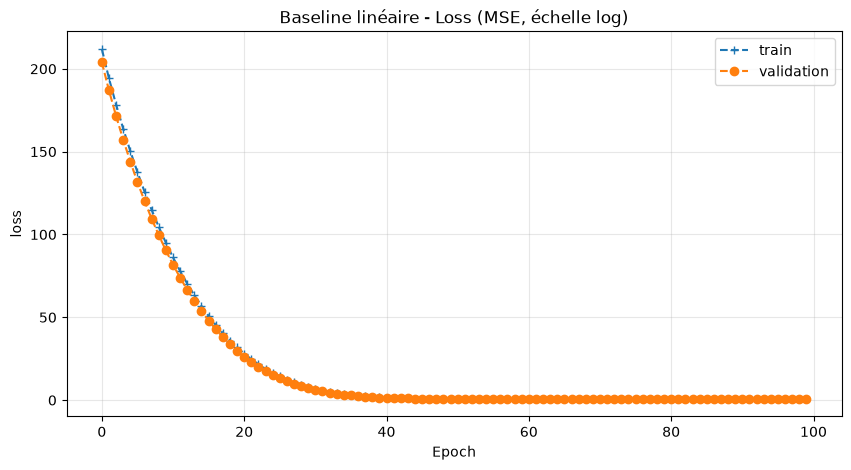

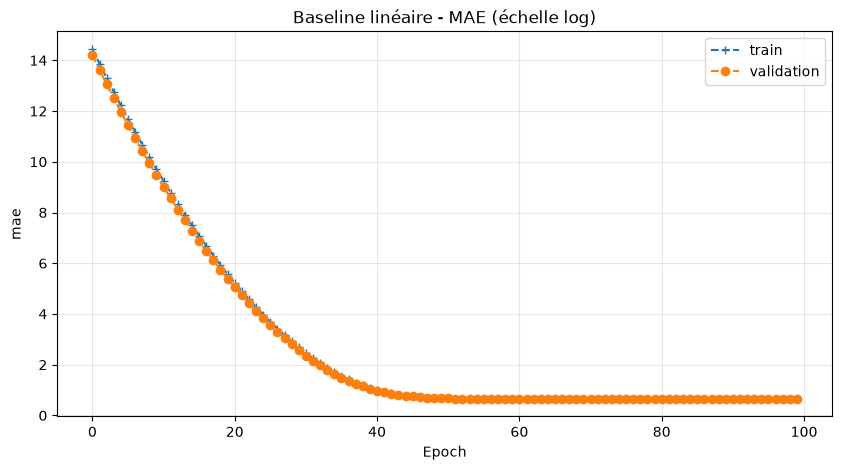

In [220]:
# Fonction pour tracer les courbes d'entraînement
def plot_history(history, metric='loss', title=None):
    plt.figure()
    plt.plot(history.history[metric], linestyle='--', marker='+', label='train')
    plt.plot(history.history[f'val_{metric}'], linestyle='--', marker='o', label='validation')
    plt.title(title or metric)
    plt.xlabel('Epoch')
    plt.ylabel(metric)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_history(history_baseline, 'loss', 'Baseline linéaire - Loss (MSE, échelle log)')
plot_history(history_baseline, 'mae', 'Baseline linéaire - MAE (échelle log)')

Sur ces deux graphiques, la courbe "train" (en pointillés avec des +) est presque entièrement cachée derrière la courbe "validation" (en pointillés avec des ronds). Les deux courbes sont bien tracées, mais elles se superposent presque parfaitement du début à la fin de l'entraînement. 

Le modèle obtient donc des erreurs très proches sur les données d'entraînement et sur les données de validation.

Aucun sur-apprentissage important n'est visible sur ces courbes. Ce résultat est cohérent avec la faible complexité de la baseline linéaire, qui ne contient qu'une seule couche sans fonction d'activation.

## 6. Architecture Deep Learning : Multi-Layer Perceptron

La baseline linéaire de la section précédente ne peut représenter qu'une relation en ligne droite entre les variables d'entrée et la valeur marchande.Or certaines relations observées pendant l'EDA sont plus complexes. Par exemple, la valeur marchande en fonction de l'âge augmente d'abord, puis diminue après un certain âge. 

Un Multi-Layer Perceptron est donc testé. Il contient deux couches cachées de 64 neurones avec une fonction d'activation ReLU. Ces couches permettent au réseau d'apprendre des relations non linéaires entre les variables.

La couche de sortie contient un seul neurone sans fonction d'activation, car le modèle doit prédire une valeur numérique.

In [221]:
# Architecture du MLP : deux couches cachées de 64 neurones
def build_mlp(input_dim):
    model = keras.Sequential(name="MLP_Valorisation")
    model.add(keras.layers.Input(shape=(input_dim,), name="InputLayer"))
    model.add(keras.layers.Dense(64, activation='relu', name="Dense_1"))
    model.add(keras.layers.Dense(64, activation='relu', name="Dense_2"))
    model.add(keras.layers.Dense(1, name="Output"))
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

mlp_model = build_mlp(X_train.shape[1])
mlp_model.summary()

Model: "MLP_Valorisation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Dense_1 (Dense)                 │ (None, 64)             │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,017 (23.50 KB)

 Trainable params: 6,017 (23.50 KB)

 Non-trainable params: 0 (0.00 B)

In [222]:
# Vérification manuelle du nombre de paramètres de la première couche dense
# (nombre d'entrées * nombre de neurones + un biais par neurone)
n_features = X_train.shape[1]
print(f"Dense_1 attendu : {n_features} * 64 + 64 = {n_features * 64 + 64}")

Dense_1 attendu : 27 * 64 + 64 = 1792


MLP - validation - MAE : 4.9M€ | Erreur absolue médiane : 1.1M€


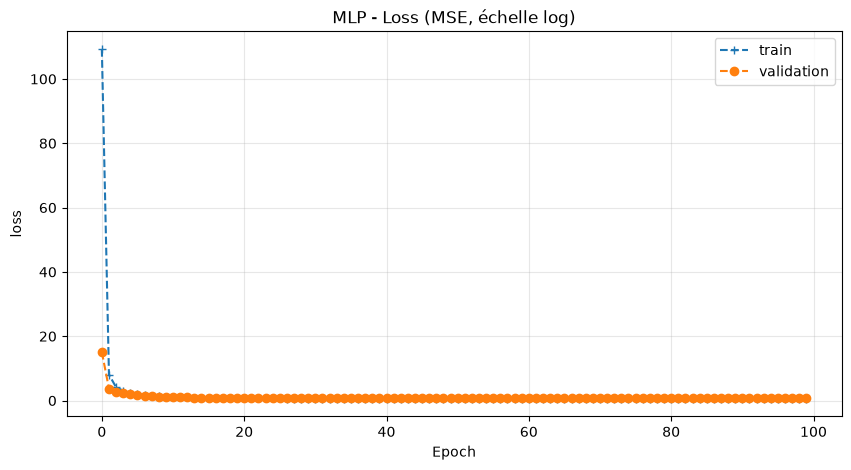

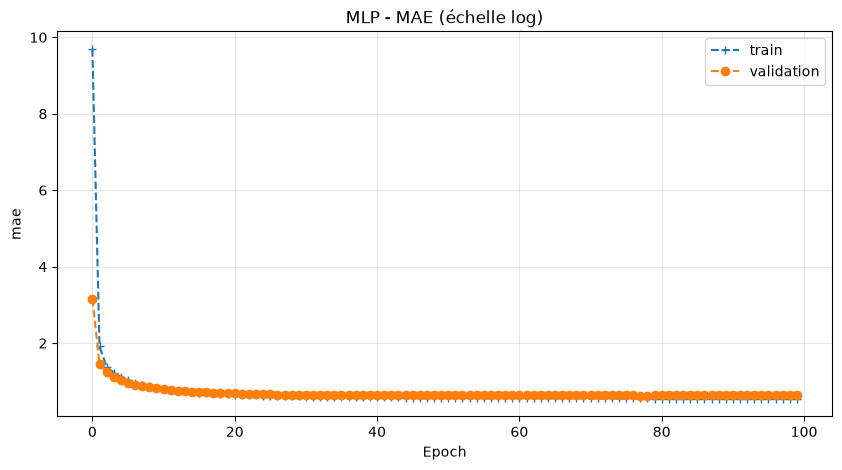

In [223]:
# Entraînement du MLP
history_mlp = mlp_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    verbose=0
)

y_pred_mlp_log = mlp_model.predict(X_val, verbose=0).flatten()
mae_mlp_val, medae_mlp_val = evaluate_eur(y_val, y_pred_mlp_log, "MLP - validation")

plot_history(history_mlp, 'loss', 'MLP - Loss (MSE, échelle log)')
plot_history(history_mlp, 'mae', 'MLP - MAE (échelle log)')

In [224]:
# Comparaison rapide des trois modèles sur le validation set
print("Baseline triviale (validation) :", format_eur(mae_trivial_val))
print("Baseline linéaire (validation) :", format_eur(mae_baseline_val))
print("MLP               (validation) :", format_eur(mae_mlp_val))

Baseline triviale (validation) : 7.1M€
Baseline linéaire (validation) : 4.0M€
MLP               (validation) : 4.9M€


Le MLP sans régularisation obtient de meilleurs résultats que la baseline triviale, mais il fait moins bien que la baseline linéaire sur le validation set.

La transformation logarithmique de la cible et les variables utilisées rendent probablement une partie importante de la relation plus simple à modéliser. La baseline linéaire arrive donc déjà à représenter une grande partie de la relation entre les caractéristiques des joueurs et leur valeur marchande.

Le premier MLP contient deux couches de 64 neurones et possède beaucoup plus de paramètres que la baseline linéaire. Avec environ 3 700 joueurs dans le train set et sans régularisation, cette complexité supplémentaire ne permet pas forcément de mieux généraliser sur les données de validation.

Cela ne signifie pas que le Deep Learning n’est pas adapté au problème. Ce premier MLP sert de point de départ. La section suivante teste une architecture plus petite, de la régularisation, plusieurs optimiseurs et différents learning rates afin de trouver une configuration mieux adaptée au dataset.

Ces modèles sont comparés ici uniquement sur le validation set. Le test set reste réservé à l’évaluation finale de la section 8.

## 7. Optimisation et amélioration

Cette section applique au problème les techniques de régularisation et d'optimisation vues en cours : taille du réseau, régularisation (L2, Dropout), choix de l'optimiseur, réglage du learning rate.

### 7.1 Effet de la taille du modèle

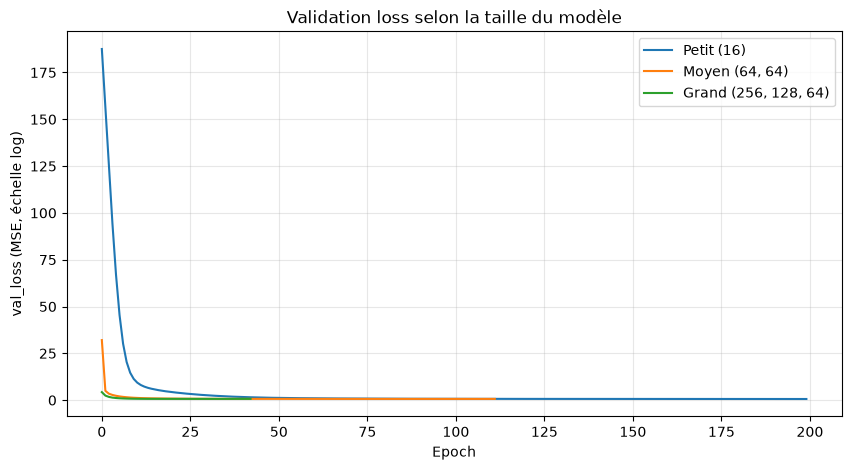

In [ ]:
# Trois architectures de tailles différentes, pour comparer leur effet sur l'apprentissage
def build_small_model(input_dim):
    model = keras.Sequential(name="MLP_Petit")
    model.add(keras.layers.Input(shape=(input_dim,)))
    model.add(keras.layers.Dense(16, activation='relu'))
    model.add(keras.layers.Dense(1))
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

def build_medium_model(input_dim):
    model = keras.Sequential(name="MLP_Moyen")
    model.add(keras.layers.Input(shape=(input_dim,)))
    model.add(keras.layers.Dense(64, activation='relu'))
    model.add(keras.layers.Dense(64, activation='relu'))
    model.add(keras.layers.Dense(1))
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

def build_large_model(input_dim):
    model = keras.Sequential(name="MLP_Grand")
    model.add(keras.layers.Input(shape=(input_dim,)))
    model.add(keras.layers.Dense(256, activation='relu'))
    model.add(keras.layers.Dense(128, activation='relu'))
    model.add(keras.layers.Dense(64, activation='relu'))
    model.add(keras.layers.Dense(1))
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

models_to_compare = {
    'Petit (16)': build_small_model(X_train.shape[1]),
    'Moyen (64, 64)': build_medium_model(X_train.shape[1]),
    'Grand (256, 128, 64)': build_large_model(X_train.shape[1]),
}

histories_capacity = {}
for name, model in models_to_compare.items():
    # EarlyStopping pour que le modèle gardé en mémoire soit bien celui du meilleur epoch,
    # cohérent avec le "Meilleure val_loss" affiché dans le tableau récapitulatif ci-dessous
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=64,
                  callbacks=[early_stop], verbose=0)
    histories_capacity[name] = h

plt.figure()
for name, h in histories_capacity.items():
    plt.plot(h.history['val_loss'], label=name)
plt.title("Validation loss selon la taille du modèle")
plt.xlabel("Epoch")
plt.ylabel("val_loss (MSE, échelle log)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Résumé numérique : minimum de validation loss, epoch correspondante et MAE en euros sur le validation set, pour chaque taille de modèle
resume_taille = []
for name, h in histories_capacity.items():
    val_losses = h.history['val_loss']
    best_epoch = val_losses.index(min(val_losses))
    y_pred = models_to_compare[name].predict(X_val, verbose=0).flatten()
    mae_eur = mean_absolute_error(np.expm1(y_val), to_eur(y_pred))
    resume_taille.append({
        'Modèle': name,
        'Meilleure val_loss': round(min(val_losses), 4),
        'Epoch': best_epoch + 1,
        'MAE validation (€)': format_eur(mae_eur),
    })
pd.DataFrame(resume_taille)

,Modèle,Meilleure val_loss,Epoch,MAE validation (€)
0,Petit (16),0.6151,200,4.3M€
1,"Moyen (64, 64)",0.6599,97,4.5M€
2,"Grand (256, 128, 64)",0.6777,28,4.7M€


Le tableau confirme le graphique : 

le modèle "Petit" a à la fois la meilleure validation loss (0,615) et la meilleure MAE en euros (4,3M€). Les architectures plus grandes font moins bien sur les deux critères. C'est cohérent avec la taille du jeu d'entraînement, environ 3700 lignes : un réseau plus large possède davantage de paramètres à ajuster, mais pas plus de données pour les apprendre. Cette capacité supplémentaire n’apporte pas d’amélioration ici et peut rendre l’entraînement moins stable ou favoriser le sur-apprentissage.

Le modèle « Petit » a atteint les 200 epochs sans déclencher l'EarlyStopping. Cela signifie que la validation loss a encore connu des améliorations pendant l'entraînement, même si elles peuvent être faibles. 

Parmi les architectures testées, le petit modèle donne les meilleurs résultats. Il est donc conservé pour la suite de l'optimisation (régularisation, optimiseur, learning rate).

### 7.2 Régularisation : L2 et Dropout

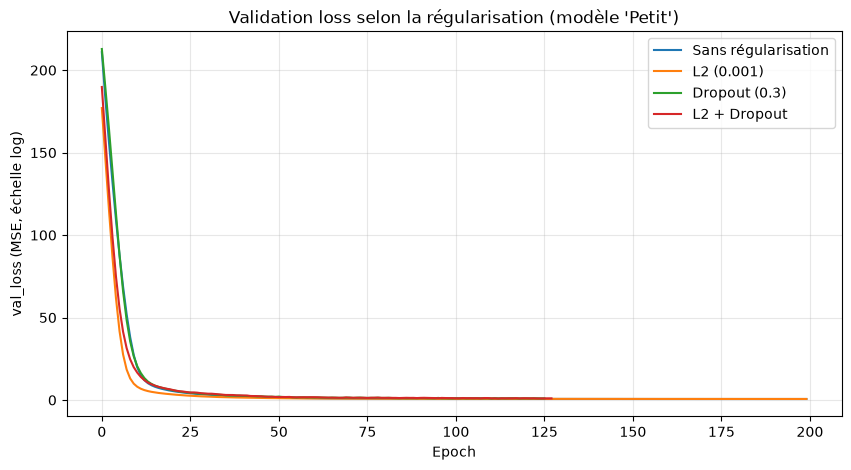

In [ ]:
# Architecture "Petit" (celle qui a gagné en 7.1), avec en plus la possibilité d'ajouter de la régularisation L2 et/ou du Dropout
def build_model(input_dim, l2=0.0, dropout=0.0):
    reg = regularizers.l2(l2) if l2 > 0 else None

    model = keras.Sequential(name="MLP_regularized")
    model.add(keras.layers.Input(shape=(input_dim,)))
    model.add(keras.layers.Dense(16, activation='relu', kernel_regularizer=reg))
    if dropout > 0:
        model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(1, name="Output"))
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

reg_variants = {
    'Sans régularisation': dict(l2=0.0, dropout=0.0),
    'L2 (0.001)': dict(l2=0.001, dropout=0.0),
    'Dropout (0.3)': dict(l2=0.0, dropout=0.3),
    'L2 + Dropout': dict(l2=0.001, dropout=0.3),
}

histories_reg = {}
models_reg = {}
for name, params in reg_variants.items():
    model = build_model(X_train.shape[1], **params)
    # Même EarlyStopping que ci-dessus (7.1), pour la même raison : garder les poids du meilleur epoch plutôt que ceux du dernier
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=64,
                  callbacks=[early_stop], verbose=0)
    histories_reg[name] = h
    models_reg[name] = model

plt.figure()
for name, h in histories_reg.items():
    plt.plot(h.history['val_loss'], label=name)
plt.title("Validation loss selon la régularisation (modèle 'Petit')")
plt.xlabel("Epoch")
plt.ylabel("val_loss (MSE, échelle log)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Résumé numérique : minimum de validation loss, epoch correspondante et MAE en euros sur le validation set, pour chacune des quatre configurations
resume_reg = []
for name, h in histories_reg.items():
    val_losses = h.history['val_loss']
    best_epoch = val_losses.index(min(val_losses))
    y_pred = models_reg[name].predict(X_val, verbose=0).flatten()
    mae_eur = mean_absolute_error(np.expm1(y_val), to_eur(y_pred))
    resume_reg.append({
        'Configuration': name,
        'Meilleure val_loss': round(min(val_losses), 4),
        'Epoch': best_epoch + 1,
        'MAE validation (€)': format_eur(mae_eur),
    })
pd.DataFrame(resume_reg)

,Configuration,Meilleure val_loss,Epoch,MAE validation (€)
0,Sans régularisation,0.6284,200,4.4M€
1,L2 (0.001),0.6414,200,4.0M€
2,Dropout (0.3),0.9166,111,4.6M€
3,L2 + Dropout,0.9254,113,4.4M€


Sur le petit modèle, les configurations utilisant du Dropout obtiennent les moins bons résultats en validation loss. Le Dropout seul donne également la MAE la plus élevée, autour de 4,6 millions d'euros.

Le réseau ne contient qu'une couche cachée de 16 neurones. Avec un Dropout de 30 %, une partie importante de ces neurones est désactivée pendant chaque étape d'entraînement. Cela peut réduire trop fortement la capacité du modèle.

Les résultats sans régularisation et avec L2 sont plus proches. La configuration sans régularisation obtient la meilleure validation loss, avec 0,628, tandis que L2 obtient la meilleure MAE en euros, autour de 4 millions d'euros.

La régularisation L2 avec un coefficient de 0,001 est donc retenue. Elle obtient la meilleure MAE tout en conservant une validation loss proche de la meilleure configuration.


### 7.3 Comparaison d'optimiseurs

Pour comparer les optimiseurs dans des conditions équivalentes, les trois utilisent le même learning rate : 0.001, la valeur par défaut d'Adam et de RMSprop dans Keras.

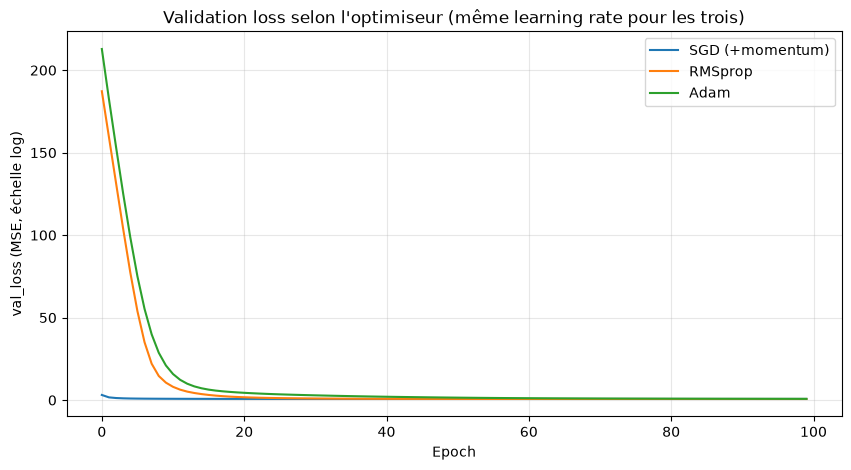

In [ ]:
# Comparaison de trois optimiseurs à learning rate identique
optimizers_to_try = {
    'SGD (+momentum)': keras.optimizers.SGD(learning_rate=0.001, momentum=0.9),
    'RMSprop': keras.optimizers.RMSprop(),
    'Adam': keras.optimizers.Adam(),
}

histories_opt = {}
for name, opt in optimizers_to_try.items():
    # Même seed avant chaque entraînement pour limiter l'effet de l'initialisation
    tf.random.set_seed(42)
    model = build_model(X_train.shape[1], l2=0.001, dropout=0.0)
    model.compile(optimizer=opt, loss='mse', metrics=['mae'])
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=64, verbose=0)
    if np.isnan(h.history['val_loss']).any():
        print(f"{name} : la validation loss est devenue NaN (l'entraînement a divergé).")
    histories_opt[name] = h

plt.figure()
for name, h in histories_opt.items():
    plt.plot(h.history['val_loss'], label=name)
plt.title("Validation loss selon l'optimiseur (même learning rate pour les trois)")
plt.xlabel("Epoch")
plt.ylabel("val_loss (MSE, échelle log)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

les trois optimiseurs démarrent avec des poids initiaux identiques (la seed est réinitialisée avant chaque entrainement). Ils finissent tous par converger vers un niveau de validation loss très bas et proche, mais leurs trajectoires restent très différentes au départ. 

Adam et RMSprop partent d'une validation loss très élevée, entre 190 et 215, et mettent une dizaine d'epochs à redescendre à un niveau raisonnable. SGD avec momentum, lui, reste bas et stable dès le premier epoch. Comme les trois modèles démarrent avec exactement les mêmes poids, ce pic de départ ne vient pas de l'initialisation aléatoire mais du fonctionnement des optimiseurs et de leurs mises à jour des poids. Il est cependant difficile d'expliquer précisément le pic observé pour Adam et RMSprop avec juste cette  expérience.

Cette comparaison reste surtout pédagogique : normalement, chaque optimiseur devrait être réglé séparément, un même learning rate n'étant pas forcément optimal pour les trois. La bonne tenue de SGD ici ne le désigne donc pas forcément comme le meilleur choix dans l'absolu. 

Adam est retenu pour la suite du notebook car il atteint de bons résultats après convergence, c'est l'optimiseur le plus utilisé pour ce type de problème, et il est généralement moins sensible à un mauvais réglage manuel du learning rate.


### 7.4 Recherche du meilleur learning rate

Plusieurs learning rates sont testés avec l'optimiseur Adam, l'architecture « Petit » et la régularisation L2.

Les modèles sont comparés à partir de la MAE et du RMSE calculés en euros sur le validation set. La MAE en échelle logarithmique est également affichée, mais les métriques en euros sont plus faciles à interpréter dans le contexte du projet.

Le test set n'est pas utilisé pendant cette comparaison. Il reste réservé à l'évaluation finale de la section 8.


In [ ]:
# Chaque candidat est entraîné avec la configuration complète du modèle final

lr_models = {}
lr_comparison = []
for lr in [0.01, 0.005, 0.001, 0.0005]:
    model = build_model(X_train.shape[1], l2=0.001, dropout=0.0)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='mse', metrics=['mae'])
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=200, batch_size=64, callbacks=[early_stop], verbose=0)

    y_pred_log = model.predict(X_val, verbose=0).flatten()
    y_pred_eur = to_eur(y_pred_log)
    y_val_eur_lr = np.expm1(y_val)
    mae_lr = mean_absolute_error(y_val_eur_lr, y_pred_eur)
    rmse_lr = np.sqrt(mean_squared_error(y_val_eur_lr, y_pred_eur))

    lr_models[lr] = {'model': model, 'history': h}
    lr_comparison.append({
        'learning_rate': lr,
        'val_mae (echelle log)': round(min(h.history['val_mae']), 3),
        'MAE_validation': format_eur(mae_lr),
        'RMSE_validation': format_eur(rmse_lr),
    })

pd.DataFrame(lr_comparison)

,learning_rate,val_mae (echelle log),MAE_validation,RMSE_validation
0,0.0100,0.637,4.8M€,13.5M€
1,0.0050,0.611,4.0M€,10.3M€
2,0.0010,0.601,4.0M€,10.2M€
3,0.0005,0.652,4.2M€,11.3M€


Le learning rate 0,001 obtient le meilleur résultat sur les trois métriques à la fois : la meilleure MAE de validation en échelle log (0,601), la meilleure MAE en euros à égalité avec 0,005 (4,0M€), et le meilleur RMSE (10,2M€ contre 10,3M€ pour 0,005). Les learning rates plus extrêmes, 0,01 et 0,0005, font clairement moins bien sur les trois critères. Le learning rate 0,001 est donc retenu pour le modèle final.

### 7.5 Modèle final

Le modèle final reprend la meilleure configuration trouvée pendant les expériences précédentes : l'architecture « Petit », la régularisation L2, l'optimiseur Adam et un learning rate de 0,001.

Le modèle entraîné dans la section précédente est directement utilisé. Il n'est donc pas entraîné une nouvelle fois avant l'évaluation.

L'`EarlyStopping` arrête l'entraînement lorsque la validation loss ne s'améliore plus pendant 15 epochs consécutives. L'option `restore_best_weights=True` permet de restaurer les poids correspondant à la meilleure validation loss obtenue pendant l'entraînement.


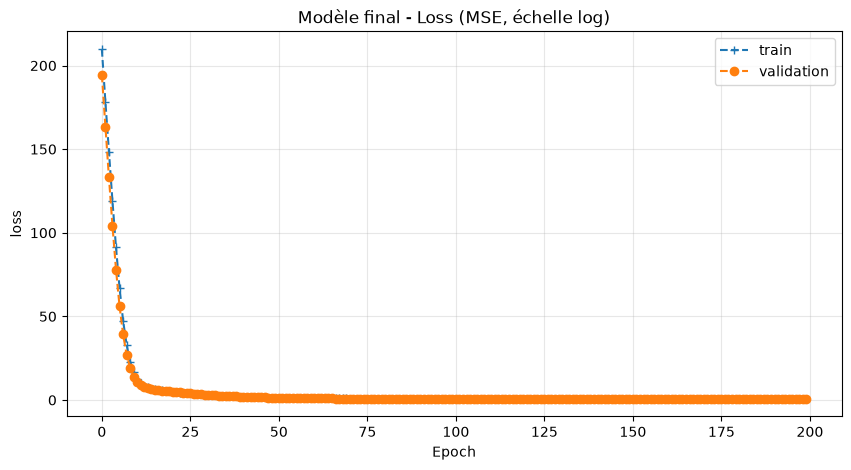

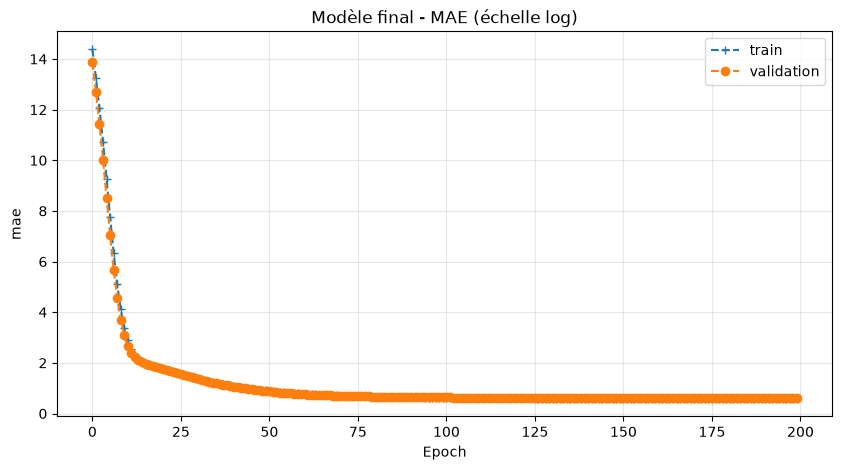

In [282]:
# Le modèle final reprend directement le meilleur candidat trouvé en 7.4
FINAL_LR = 0.001
final_model = lr_models[FINAL_LR]['model']
history_final = lr_models[FINAL_LR]['history']

plot_history(history_final, 'loss', 'Modèle final - Loss (MSE, échelle log)')
plot_history(history_final, 'mae', 'Modèle final - MAE (échelle log)')

## 8. Évaluation du modèle final

Les choix de l'architecture, de la régularisation et du learning rate ont été réalisés à partir du validation set. Le test set n'a donc pas été utilisé pour sélectionner ou modifier les modèles.

Cette section permet maintenant de comparer les performances finales de la baseline triviale, de la baseline linéaire, du premier MLP et du modèle final.

Les résultats d'un réseau de neurones peuvent varier selon l'initialisation de ses poids. La baseline linéaire, le MLP sans régularisation et le modèle final sont donc entraînés cinq fois avec des seeds différentes.

Les hyperparamètres restent identiques pendant ces entraînements. La MAE moyenne permet simplement d'obtenir une comparaison moins dépendante d'une seule initialisation.


In [291]:
# Évaluation du modèle final sur le test set
y_pred_log = final_model.predict(X_test, verbose=0).flatten()
y_pred_eur = to_eur(y_pred_log)
y_test_eur = np.expm1(y_test)

mae_final, medae_final = evaluate_eur(y_test, y_pred_log, "Modèle final")
rmse_final = np.sqrt(mean_squared_error(y_test_eur, y_pred_eur))
r2_final = r2_score(y_test, y_pred_log)

print("RMSE :", format_eur(rmse_final))
print(f"R2 (échelle log) : {r2_final:.3f}")
print()
print("Prédiction la plus haute avant plafonnement :", format_eur(np.expm1(y_pred_log.max())))
print("Valeur maximale observée à l'entraînement (le plafond utilisé) :", format_eur(np.expm1(VALEUR_LOG_MAX)))

Modèle final - MAE : 4.1M€ | Erreur absolue médiane : 1.1M€
RMSE : 9.5M€
R2 (échelle log) : 0.720

Prédiction la plus haute avant plafonnement : 141.3M€
Valeur maximale observée à l'entraînement (le plafond utilisé) : 200.0M€


Sur ce test précis, la prédiction la plus haute (141,3M€) reste sous le plafond fixé en section 4.9 (200M€). 
Le plafonnement n'a donc pas eu besoin d'intervenir ici. Il reste quand même utile comme garde-fou : rien n'empêche qu'un futur joueur, avec un profil statistique très inhabituel, pousse le modèle à prédire une valeur totalement irréaliste une fois reconvertie en euros. Cette précaution évite qu'un seul cas de ce genre fausse toutes les métriques du notebook.

In [ ]:
# Première évaluation sur le test set avec seed 42
y_pred_trivial_test = np.full_like(y_test, fill_value=median_log_value)
mae_trivial, medae_trivial = evaluate_eur(y_test, y_pred_trivial_test, "Baseline triviale (médiane)")

y_pred_baseline_test = baseline_model.predict(X_test, verbose=0).flatten()
mae_baseline, medae_baseline = evaluate_eur(y_test, y_pred_baseline_test, "Baseline linéaire")

y_pred_mlp_test = mlp_model.predict(X_test, verbose=0).flatten()
mae_mlp, medae_mlp = evaluate_eur(y_test, y_pred_mlp_test, "MLP (sans régularisation)")

Baseline triviale (médiane) - MAE : 6.8M€ | Erreur absolue médiane : 2.0M€
Baseline linéaire - MAE : 4.0M€ | Erreur absolue médiane : 1.2M€
MLP (sans régularisation) - MAE : 4.1M€ | Erreur absolue médiane : 1.3M€


La baseline linéaire, le MLP sans régularisation et le modèle final sont réentraînés avec 4 seeds supplémentaires, en plus de la seed 42 déjà utilisée ci-dessus. On obtient ainsi une MAE moyenne sur 5 entraînements, plutôt qu'un seul essai. La baseline triviale, elle, n'a pas de poids aléatoires : elle prédit toujours la médiane du train, donc un seul calcul suffit pour elle.

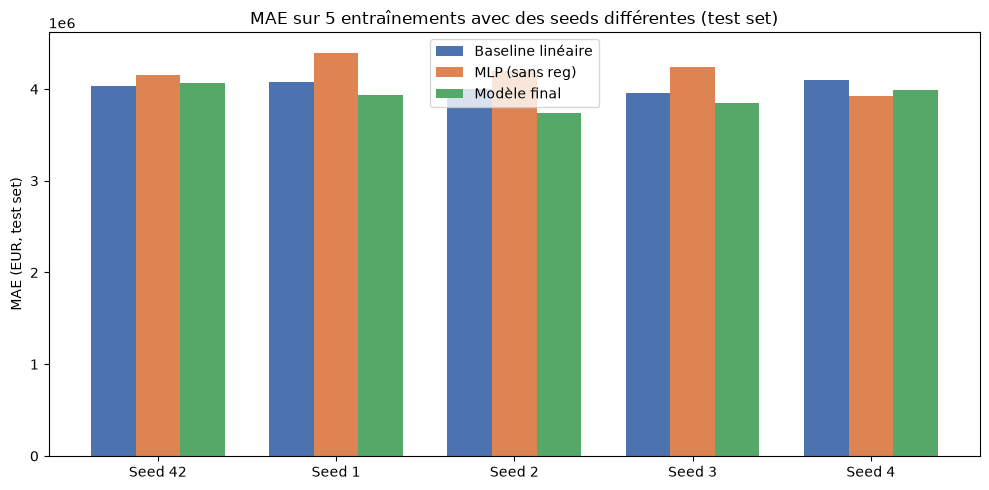

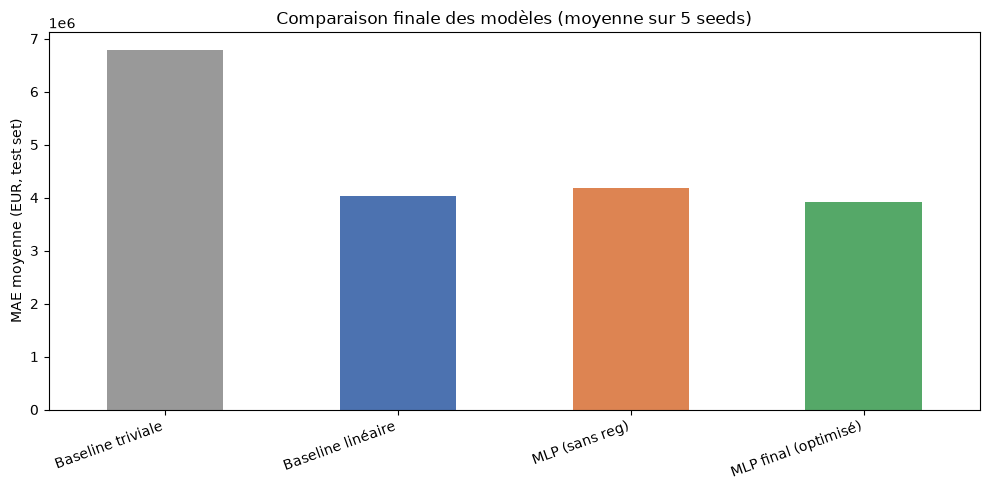

Baseline triviale       6.8M€
Baseline linéaire       4.0M€
MLP (sans reg)          4.2M€
MLP final (optimisé)    3.9M€
dtype: str

In [301]:
# Ré-entraînement avec 4 seeds supplémentaires, puis comparaison finale
maes_baseline_repeats = [mae_baseline]
maes_mlp_repeats = [mae_mlp]
maes_final_repeats = [mae_final]

for seed in [1, 2, 3, 4]:
    tf.random.set_seed(seed)

    m_base = build_linear_baseline(X_train.shape[1])
    m_base.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=64, verbose=0)
    pred_base = m_base.predict(X_test, verbose=0).flatten()
    maes_baseline_repeats.append(mean_absolute_error(y_test_eur, to_eur(pred_base)))

    m_mlp = build_mlp(X_train.shape[1])
    m_mlp.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=64, verbose=0)
    pred_mlp = m_mlp.predict(X_test, verbose=0).flatten()
    maes_mlp_repeats.append(mean_absolute_error(y_test_eur, to_eur(pred_mlp)))

    m_final = build_model(X_train.shape[1], l2=0.001, dropout=0.0)
    m_final.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    m_final.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=64,
                callbacks=[early_stop], verbose=0)
    pred_final = m_final.predict(X_test, verbose=0).flatten()
    maes_final_repeats.append(mean_absolute_error(y_test_eur, to_eur(pred_final)))

# On remet la seed d'origine pour ne pas perturber la suite du notebook (section 9)
np.random.seed(42)
tf.random.set_seed(42)

# Graphique 1 : le detail des 5 seeds pour chaque modele a poids aleatoires
x = np.arange(5)
width = 0.25

plt.figure()
plt.bar(x - width, maes_baseline_repeats, width, label='Baseline linéaire', color='#4C72B0')
plt.bar(x, maes_mlp_repeats, width, label='MLP (sans reg)', color='#DD8452')
plt.bar(x + width, maes_final_repeats, width, label='Modèle final', color='#55A868')
plt.xticks(x, ['Seed 42', 'Seed 1', 'Seed 2', 'Seed 3', 'Seed 4'])
plt.ylabel('MAE (EUR, test set)')
plt.title('MAE sur 5 entraînements avec des seeds différentes (test set)')
plt.legend()
plt.tight_layout()
plt.show()

# Graphique 2 : comparaison finale sur les moyennes des 5 seeds (+ baseline triviale, fixe)
comparison_moyenne = pd.Series({
    'Baseline triviale': mae_trivial,
    'Baseline linéaire': np.mean(maes_baseline_repeats),
    'MLP (sans reg)': np.mean(maes_mlp_repeats),
    'MLP final (optimisé)': np.mean(maes_final_repeats),
})

plt.figure()
comparison_moyenne.plot(kind='bar', color=['#999999', '#4C72B0', '#DD8452', '#55A868'])
plt.ylabel('MAE moyenne (EUR, test set)')
plt.title('Comparaison finale des modèles (moyenne sur 5 seeds)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

comparison_moyenne.apply(format_eur)

Sur les cinq entraînements, le modèle final obtient la MAE moyenne la plus faible, avec environ 3,9 millions d'euros. Il devance légèrement la baseline linéaire, qui obtient 4 millions d'euros, et le MLP sans régularisation, avec 4,2 millions d'euros. 

Les trois modèles utilisent les variables du dataset et obtiennent de meilleurs résultats que la baseline triviale, dont la MAE est de 6,8 millions d'euros.

Le modèle final donne donc le meilleur résultat moyen, mais le gain par rapport à la baseline linéaire reste faible, avec environ 100 000 € de différence. Avec seulement cinq entraînements, cette différence doit être interprétée avec prudence.


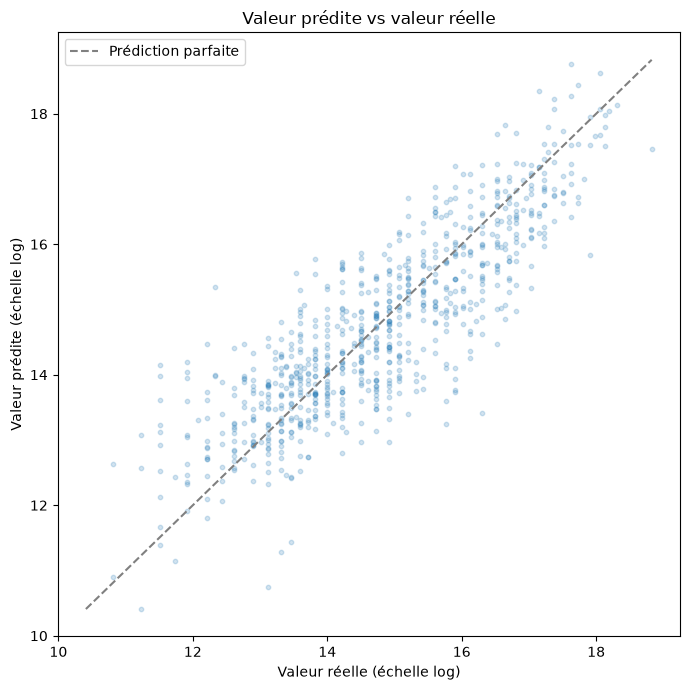

In [286]:
# Valeur prédite vs valeur réelle sur le test set
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_log, alpha=0.2, s=10)
lims = [min(y_test.min(), y_pred_log.min()), max(y_test.max(), y_pred_log.max())]
plt.plot(lims, lims, '--', color='gray', label='Prédiction parfaite')
plt.xlabel("Valeur réelle (échelle log)")
plt.ylabel("Valeur prédite (échelle log)")
plt.title("Valeur prédite vs valeur réelle")
plt.legend()
plt.tight_layout()
plt.show()

### Joueurs potentiellement sous-évalués et surévalués selon le modèle

In [287]:
test_results = test_df[['player_id']].copy()
test_results['market_value_actual'] = y_test_eur
test_results['market_value_predicted'] = y_pred_eur
test_results['residual'] = test_results['market_value_actual'] - test_results['market_value_predicted']
test_results = test_results.merge(players[['player_id', 'name', 'position', 'current_club_name']], on='player_id', how='left')

# Colonnes affichées en format lisible (ex. 90.0M€) plutôt qu'en nombres bruts
def format_table(table):
    table = table.copy()
    for col in ['market_value_actual', 'market_value_predicted', 'residual']:
        table[col] = table[col].apply(format_eur)
    return table[['name', 'position', 'current_club_name', 'market_value_actual', 'market_value_predicted', 'residual']]

print("Joueurs les plus sous-évalués (le modèle prédit une valeur bien plus haute que la valeur réelle) :")
undervalued = test_results.sort_values('residual').head(15)
format_table(undervalued)

Joueurs les plus sous-évalués (le modèle prédit une valeur bien plus haute que la valeur réelle) :


,name,position,current_club_name,market_value_actual,market_value_predicted,residual
134,Malick Thiaw,Defender,Newcastle United Football Club,45.0M€,141.3M€,-96.3M€
127,Nikola Milenković,Defender,Nottingham Forest Football Club,28.0M€,93.5M€,-65.5M€
577,Victor Froholdt,Midfield,Futebol Clube do Porto,50.0M€,102.4M€,-52.4M€
546,Luis Díaz,Attack,FC Bayern München,70.0M€,122.0M€,-52.0M€
541,Dango Ouattara,Attack,Brentford Football Club,35.0M€,82.5M€,-47.5M€
471,Ibrahima Konaté,Defender,Liverpool Football Club,45.0M€,86.5M€,-41.5M€
380,Nilson Angulo,Attack,Sunderland Association Football Club,17.0M€,55.2M€,-38.2M€
26,Malo Gusto,Defender,Chelsea Football Club,35.0M€,70.3M€,-35.3M€
111,Hyeon-gyu Oh,Attack,Beşiktaş Jimnastik Kulübü,15.0M€,48.2M€,-33.2M€
663,Leopold Querfeld,Defender,1. Fußballclub Union Berlin,20.0M€,48.6M€,-28.6M€


In [288]:
# Joueurs les plus surévalués
print("Joueurs les plus surévalués (le modèle prédit une valeur bien plus basse que la valeur réelle) :")
overvalued = test_results.sort_values('residual', ascending=False).head(15)
format_table(overvalued)

Joueurs les plus surévalués (le modèle prédit une valeur bien plus basse que la valeur réelle) :


,name,position,current_club_name,market_value_actual,market_value_predicted,residual
312,Pedri,Midfield,Futbol Club Barcelona,150.0M€,38.3M€,111.7M€
54,Dean Huijsen,Defender,Real Madrid Club de Fútbol,60.0M€,7.5M€,52.5M€
673,Matheus Cunha,Attack,Manchester United Football Club,75.0M€,39.7M€,35.3M€
486,Nicolò Barella,Midfield,Football Club Internazionale Milano S.p.A.,50.0M€,16.6M€,33.4M€
611,Samu Aghehowa,Attack,Futebol Clube do Porto,45.0M€,13.4M€,31.6M€
213,Eduardo Camavinga,Midfield,Real Madrid Club de Fútbol,50.0M€,18.5M€,31.5M€
450,Riccardo Calafiori,Defender,Arsenal Football Club,55.0M€,24.0M€,31.0M€
303,Valentín Barco,Midfield,Racing Club de Strasbourg Alsace,40.0M€,16.7M€,23.3M€
90,Adam Wharton,Midfield,Crystal Palace Football Club,70.0M€,47.0M€,23.0M€
668,Cristian Romero,Defender,Tottenham Hotspur Football Club,45.0M€,22.4M€,22.6M€


### Discussion critique

#### Interprétation des résultats

Le modèle final obtient une MAE d'environ 4,1 millions d'euros, une erreur absolue médiane d'environ 1,1 million d'euros et un R² de 0,72 en échelle logarithmique sur le test set.

Le R² montre que le modèle explique une partie importante des différences de valeur marchande entre les joueurs, même si les prédictions restent imparfaites.

La comparaison sur cinq entraînements donne une MAE moyenne de 3,9 millions d'euros pour le modèle final, contre 4 millions pour la baseline linéaire et 4,2 millions pour le MLP sans régularisation. Le modèle final est donc légèrement meilleur en moyenne, mais l'écart avec la baseline linéaire reste faible.

La différence entre la MAE de 4,1 millions d'euros et l'erreur médiane de 1,1 million montre que quelques joueurs provoquent des erreurs très importantes. Pour la moitié des joueurs du test set, l'erreur reste inférieure à environ 1,1 million d'euros. Les erreurs de plusieurs dizaines de millions augmentent fortement la moyenne.

Le cas le plus important parmi les joueurs considérés comme surévalués par le modèle est Pedri. Sa valeur réelle est de 150 millions d'euros, alors que le modèle prédit environ 38,3 millions, soit une différence de 111,7 millions.

Pour les joueurs potentiellement sous-évalués, Malick Thiaw possède l'écart le plus élevé. Le modèle prédit environ 141,3 millions d'euros, contre une valeur réelle de 45 millions.

Ces résultats ne signifient pas forcément que les valeurs Transfermarkt sont incorrectes. Ils montrent que les statistiques utilisées par le modèle conduisent à une estimation différente de la valeur actuelle. Un écart important peut donc signaler un profil intéressant, mais il peut aussi venir d'une erreur du modèle ou d'un profil très différent de ceux rencontrés pendant l'entraînement.


#### Ce que le modèle sait dire, et ce qu'il ne sait pas dire

Le modèle ne se base que sur la performance statistique et le profil du joueur pendant une saison. Il ne peut pas connaître le potentiel perçu par les recruteurs, la situation contractuelle d'un joueur, sa médiatisation, ou l'effet d'un agent puissant sur les négociations. Le classement des joueurs surévalués en donne un bon exemple : on y retrouve beaucoup de jeunes joueurs très prometteurs (Pedri, Dean Huijsen...). Leur valeur marchande intègre un pari sur l'avenir, que les statistiques d'une seule saison ne peuvent pas justifier à elles seules. À l'inverse, le classement des sous-évalués met en avant des joueurs dont la valeur est peut-être plus conservatrice sur le marché, malgré leurs statistiques. Ces classements doivent donc être lus comme des pistes de réflexion, pas comme des recommandations d'achat certaines.

#### Limites

Ce projet a plusieurs limites, importantes à garder en tête pour bien interpréter ses résultats :
-	Le filtre de temps de jeu minimum (450 minutes) écarte les joueurs les plus marginaux d'une équipe. Leur valeur est justement difficile à expliquer avec une saison incomplète, donc le modèle ne peut rien dire sur ce profil de joueurs.
-	Les statistiques utilisées (buts, passes décisives) sont aussi peu adaptées aux gardiens de but. Leur performance se juge sur d'autres critères : arrêts, sorties, relances.
-	Le découpage aléatoire du jeu de données ne reproduit pas non plus un vrai cas d'usage de recrutement. Dans la réalité, un club utiliserait plutôt les statistiques de la saison en cours pour anticiper la valeur de la saison suivante. C'est un problème différent, plus proche d'une prédiction temporelle, que celui traité ici.
-	Enfin, le modèle se base uniquement sur la performance sportive et le profil du joueur. Il n'intègre pas des éléments pourtant déterminants dans la réalité du marché des transferts, comme la situation contractuelle, la réputation, la médiatisation ou l'influence d'un agent. Il faut aussi rappeler que la valeur marchande Transfermarkt reste elle-même une estimation d'experts, pas un prix de transaction réel. Le modèle apprend donc à reproduire un jugement humain, avec ses propres biais possibles.

#### Pistes d'amélioration

Plusieurs pistes permettraient d'améliorer ce projet dans une prochaine version :
-	traiter les gardiens de but à part, avec des statistiques spécifiques à leur poste
-	intégrer des informations contractuelles (durée restante du contrat) pour mieux refléter la réalité du marché
-	élargir la période de référence à plusieurs saisons passées, pour augmenter la taille du jeu d'entraînement, aujourd'hui limité à environ 3 700 joueurs
-	la recherche d'hyperparamètres pourrait aussi être automatisée avec une recherche en grille ou une recherche aléatoire. Cela permettrait de tester davantage d'architectures, de coefficients de régularisation et de learning rates.
-	utiliser une validation croisée (K-Fold) plutôt qu'un seul split validation/test, pour obtenir une estimation plus robuste de la performance du modèle

## 9. Conclusion générale

L'objectif de ce projet était d'estimer la valeur marchande des joueurs de football à partir de leur profil et de leurs statistiques de performance. Les prédictions ont ensuite été comparées aux valeurs réelles afin d'identifier des joueurs potentiellement sous-évalués ou surévalués selon le modèle.

L'analyse exploratoire a montré que les valeurs marchandes sont très déséquilibrées. La majorité des joueurs ont une valeur assez faible, alors que quelques joueurs atteignent plusieurs dizaines ou centaines de millions d'euros. Une transformation logarithmique de la cible a donc été utilisée avant l'entraînement.

Plusieurs modèles ont été comparés : une baseline triviale, une baseline linéaire et différents réseaux de neurones. Les expériences ont permis de tester plusieurs tailles de réseau, la régularisation L2, le Dropout, différents optimiseurs et plusieurs learning rates.

Le modèle final est un petit MLP avec une régularisation L2, l'optimiseur Adam et un learning rate de 0,001. Sur cinq entraînements, il obtient une MAE moyenne d'environ 3,9 millions d'euros. Il est légèrement meilleur que la baseline linéaire, dont la MAE moyenne est d'environ 4 millions d'euros.

Le gain apporté par le Deep Learning reste donc limité. Une partie importante de la relation entre les variables et la valeur marchande peut déjà être représentée par un modèle linéaire. Le MLP permet cependant d'obtenir le meilleur résultat moyen parmi les modèles testés.

L'analyse des écarts entre les prédictions et les valeurs réelles permet de repérer certains profils intéressants. Ces résultats doivent néanmoins être interprétés avec prudence, car le modèle ne possède pas d'informations sur les contrats, le potentiel, la réputation ou les blessures.

Ce projet montre que le Deep Learning peut aider à analyser le marché des transferts, mais que les prédictions doivent être complétées par une analyse sportive et économique plus large.
